In [ ]:
from train.train_lstm import train_lstm_pipeline
import json
import pandas as pd
from pytorch_lightning import Trainer
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
from pytorch_lightning.loggers import CSVLogger
from tqdm import tqdm

In [ ]:
ALL_VIDEOS = [
    # ('session0', 'center'),
    # ('session0', 'left'),
    # ('session0', 'right'),
    ('session1', 'center'),
    ('session1', 'left'),
    ('session1', 'right'),
    ('session2', 'center'),
    ('session2', 'left'),
    ('session2', 'right'),
    ('session3', 'center'),
    ('session3', 'left'),
    ('session3', 'right'),
    ('session4', 'center'),
    ('session4', 'left'),
    ('session4', 'right'),
    ('session5', 'center'),
    ('session5', 'left'),
    ('session5', 'right'),
    ('session6', 'center'),
    ('session6', 'left'),
    ('session6', 'right'),
]

In [ ]:
def extract_features(car):
    speed = car.get('gt_data', {}).get('speed', None)
    features = []
    fdatas = car['fdata']
    for fdata in fdatas:
        [x1, y1], [x2, y2] = fdata['bbox']['pos']
        bbox_center = fdata['bbox']['center']
        bbox_width, bbox_height = fdata['bbox']['dims']
        bbox_area, bbox_aspect_ratio = fdata['bbox']['area'], fdata['bbox']['aspect_ratio'] # may change aspect_ratio for (width / height)
        [rx1, ry1], [rx2, ry2], [rx3, ry3], [rx4, ry4] = fdata['rotated_bbox']['pos']
        rbbox_center = fdata['rotated_bbox']['center']
        rbbox_width, rbbox_height = fdata['rotated_bbox']['dims']
        rbbox_area, rbbox_angle, rbbox_aspect_ratio = fdata['rotated_bbox']['area'], fdata['rotated_bbox']['angle'], fdata['rotated_bbox']['aspect_ratio']
        bottom_x, bottom_y = fdata['bottom']
        mask_area = fdata['mask_area']

        features.append([
            # x1, y1, x2, y2,
            # bbox_center[0], bbox_center[1],
            # bbox_width, bbox_height,
            bottom_x, bottom_y,
            bbox_aspect_ratio,
            # rx1, ry1, rx2, ry2, rx3, ry3, rx4, ry4,
            # rbbox_center[0], rbbox_center[1],
            # rbbox_width, rbbox_height,
            rbbox_angle,
            rbbox_aspect_ratio,
            mask_area,
        ])
    return {
        'features': features,
        'speed': speed
    }

In [11]:
data_list = []
for session, recording in ALL_VIDEOS:
    with open(f'results_instance/{session}_{recording}/tracked_cars_data.json', 'r') as f:
        cars = json.load(f)['cars']
        valid_cars = list(filter(lambda car: car.get('gt_data', {}).get('speed', None) is not None, cars))
        data_list.extend([extract_features(car) for car in valid_cars])


In [ ]:
input_size = len(data_list[0]['features'][0])

data_module, model, trainer, logger = train_lstm_pipeline(
    # Dataset
    data_list,

    # DataModule params
    batch_size=4,
    split_ratio=(0.8, 0.1, 0.1),
    num_workers=4,

    # LSTM params
    input_size=input_size,
    hidden_size=64,
    num_layers=2,
    output_size=1,
    learning_rate=1e-3,
    dropout=0.0,

    # Logger
    log_path='tracking_lstm_sc',

    # Trainer
    patience=7,
    epochs=200,
    log_every_n_steps=10,
)

trainer.test(model, datamodule=data_module)

In [15]:
predictions = trainer.predict(model, dataloaders=data_module.test_dataloader())
pred_df = pd.DataFrame(predictions, columns=["pred", "target"])

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [17]:
df_pred = pd.DataFrame(
    [
        (
            pred[i].item(),
            real[i].item(),
            abs(pred[i].item() - real[i].item())
        )
        for (pred, real) in predictions
        for i in range(len(pred))
    ],
    columns=["Velocidad Predicha", "Velocidad Real", "Error km/h"]
)
df_pred.head(20)

,Velocidad Predicha,Velocidad Real,Error km/h
0,67.180679,67.337997,0.157318
1,77.947510,78.073196,0.125687
2,104.380569,102.088799,2.291771
3,81.948334,81.003601,0.944733
4,72.164291,72.748802,0.584511
5,82.551727,81.712799,0.838928
6,83.531639,83.970001,0.438362
7,93.012062,90.917999,2.094063
8,64.950851,64.436401,0.514450
9,65.550629,65.019600,0.531029


KeyError: "['train_mse'] not in index"

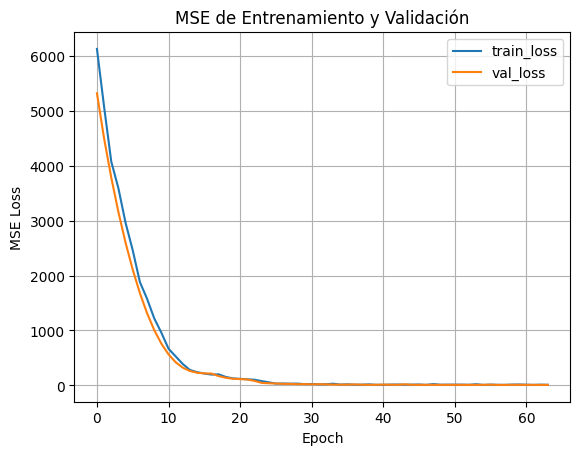

In [20]:
metrics = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")

aggreg_metrics = []
agg_col = "epoch"
for i, dfg in metrics.groupby(agg_col):
    agg = dict(dfg.mean())
    agg[agg_col] = i
    aggreg_metrics.append(agg)

df_metrics = pd.DataFrame(aggreg_metrics)

df_metrics[["train_loss", "val_loss"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch",
    ylabel="MSE Loss", 
    # ylim=(0, 500),
    title="MSE de Entrenamiento y Validación", 
)

df_metrics[["train_mse", "val_mse"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="RMSE",
    title="RMSE de Entrenamiento y Validación",
)

df_metrics[["train_mae", "val_mae"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="MAE",
    title="MAE - Entrenamiento y Validación",
)

df_metrics[["train_acc", "val_acc"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="Accuracy",
    title="Precisión Relativa de Entrenamiento y Validación",
)

